X shape: torch.Size([100, 2])  y shape: torch.Size([100, 1])
epoch   0: loss= 3001.4
epoch  50: loss= 103.9
epoch 100: loss= 68.0
epoch 150: loss= 53.4
epoch 200: loss= 49.9
epoch 250: loss= 49.8


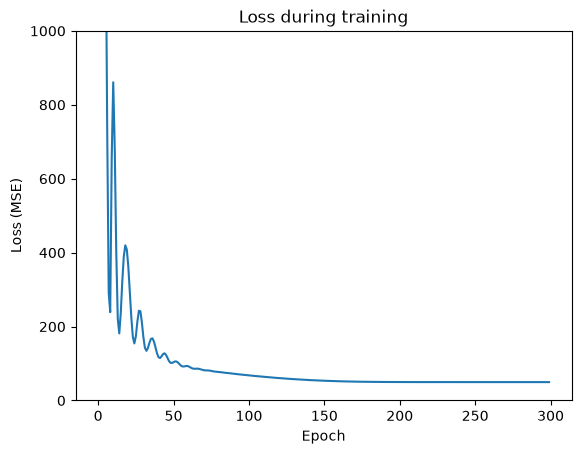

3 study hours, 2 phone hours -> 62.3 marks


In [10]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

students=pd.read_csv("students_100.csv")

X=torch.tensor(
    students[["study_hours","phone_hours"]].values, 
    dtype=torch.float32,
)
y=torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32,
)
print("X shape:",X.shape," y shape:",y.shape)

#2
torch.manual_seed(42)
model=nn.Sequential(
    nn.Linear(2,7),
    nn.ReLU(),
    nn.Linear(7,3),
    nn.ReLU(),
    nn.Linear(3,1),
)
loss_fn=nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.1)

#3
losses=[]
for epoch in range(300):
    guess=model(X)
    loss=loss_fn(guess,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 50==0:
        print(f"epoch {epoch:3}: loss= {loss.item():.1f}")

#4
plt.plot(losses)
plt.ylim(0, 1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

#5
with torch.no_grad():
    new_student=torch.tensor([[3,2]],dtype=torch.float32)
    print("3 study hours, 2 phone hours ->", round(model(new_student).item(),1),"marks")